In [1]:
!pip install ohmeow-blurr -q
!pip install datasets -q
!pip install bert-score -q

In [2]:
import datasets
import pandas as pd
from fastai.text.all import *
from transformers import *

from blurr.data.all import *
from blurr.modeling.all import *

## Data Preparation

We're going to use to use the  [datasets](https://huggingface.co/datasets) library from huggingface to grab your raw data.  This package gives you access to all kinds of NLP related datasets, explanations of each, and various task specific metrics to use in evaluating your model.  The best part being everything comes down to you in JSON!  This makes it a breeze to get up and running quickly!

We'll just use a subset of the training set to build both our training and validation DataLoaders

In [3]:
raw_data = datasets.load_dataset('cnn_dailymail', '3.0.0', split='train[:1%]')

Reusing dataset cnn_dailymail (/root/.cache/huggingface/datasets/cnn_dailymail/3.0.0/3.0.0/3cb851bf7cf5826e45d49db2863f627cba583cbc32342df7349dfe6c38060234)


In [4]:
df = pd.DataFrame(raw_data)
df.head()

,article,highlights,id
0,"It's official: U.S. President Barack Obama wants lawmakers to weigh in on whether to use military force in Syria. Obama sent a letter to the heads of the House and Senate on Saturday night, hours after announcing that he believes military action against Syrian targets is the right step to take over the alleged use of chemical weapons. The proposed legislation from Obama asks Congress to approve the use of military force ""to deter, disrupt, prevent and degrade the potential for future uses of chemical weapons or other weapons of mass destruction."" It's a step that is set to turn an internat...","Syrian official: Obama climbed to the top of the tree, ""doesn't know how to get down""\nObama sends a letter to the heads of the House and Senate .\nObama to seek congressional approval on military action against Syria .\nAim is to determine whether CW were used, not by whom, says U.N. spokesman .",0001d1afc246a7964130f43ae940af6bc6c57f01
1,"(CNN) -- Usain Bolt rounded off the world championships Sunday by claiming his third gold in Moscow as he anchored Jamaica to victory in the men's 4x100m relay. The fastest man in the world charged clear of United States rival Justin Gatlin as the Jamaican quartet of Nesta Carter, Kemar Bailey-Cole, Nickel Ashmeade and Bolt won in 37.36 seconds. The U.S finished second in 37.56 seconds with Canada taking the bronze after Britain were disqualified for a faulty handover. The 26-year-old Bolt has now collected eight gold medals at world championships, equaling the record held by American trio...",Usain Bolt wins third gold of world championship .\nAnchors Jamaica to 4x100m relay victory .\nEighth gold at the championships for Bolt .\nJamaica double up in women's 4x100m relay .,0002095e55fcbd3a2f366d9bf92a95433dc305ef
2,"Kansas City, Missouri (CNN) -- The General Services Administration, already under investigation for lavish spending, allowed an employee to telecommute from Hawaii even though he is based at the GSA's Kansas City, Missouri, office, a CNN investigation has found. It cost more than $24,000 for the business development specialist to travel to and from the mainland United States over the past year. He is among several hundred GSA ""virtual"" workers who also travel to various conferences and their home offices, costing the agency millions of dollars over the past three years. Under the program, ...","The employee in agency's Kansas City office is among hundreds of ""virtual"" workers .\nThe employee's travel to and from the mainland U.S. last year cost more than $24,000 .\nThe telecommuting program, like all GSA practices, is under review .",00027e965c8264c35cc1bc55556db388da82b07f
3,"Los Angeles (CNN) -- A medical doctor in Vancouver, British Columbia, said Thursday that California arson suspect Harry Burkhart suffered from severe mental illness in 2010, when she examined him as part of a team of doctors. Dr. Blaga Stancheva, a family physician and specialist in obstetrics, said both Burkhart and his mother, Dorothee, were her patients in Vancouver while both were applying for refugee status in Canada. ""I was asked to diagnose and treat Harry to support a claim explaining why he was unable to show up in a small-claims court case,"" Stancheva told CNN in a phone intervie...","NEW: A Canadian doctor says she was part of a team examining Harry Burkhart in 2010 .\nNEW: Diagnosis: ""autism, severe anxiety, post-traumatic stress disorder and depression""\nBurkhart is also suspected in a German arson probe, officials say .\nProsecutors believe the German national set a string of fires in Los Angeles .",0002c17436637c4fe1837c935c04de47adb18e9a
4,"(CNN) -- Police arrested another teen Thursday, the sixth suspect jailed in connection with the gang rape of a 15-year-old girl on a northern California high school campus. Jose Carlos Montano, 18, was arrested on charges of felony rape, rape in concert with force, and penetration with a foreign object, said Richmond Police L

We begin by getting our hugginface objects needed for this task (e.g., the architecture, tokenizer, config, and model).  We'll use blurr's `get_hf_objects` helper method here.

In [5]:
pretrained_model_name = "facebook/bart-large-cnn"
hf_arch, hf_config, hf_tokenizer, hf_model = BLURR.get_hf_objects(pretrained_model_name, 
                                                                  model_cls=BartForConditionalGeneration)

hf_arch, type(hf_config), type(hf_tokenizer), type(hf_model)

('bart',
 transformers.models.bart.configuration_bart.BartConfig,
 transformers.models.bart.tokenization_bart_fast.BartTokenizerFast,
 transformers.models.bart.modeling_bart.BartForConditionalGeneration)

Next we need to build out our DataBlock.  Remember tha a DataBlock is a blueprint describing how to move your raw data into something modelable.  That blueprint is executed when we pass it a data source, which in our case, will be the DataFrame we created above. We'll use a random subset to get things moving along a bit faster for the demo as well.

Notice that the blurr DataBlock as been dramatically simplified given the shift to on-the-fly batch-time tokenization.  All we need is to define a single `HF_Seq2SeqBeforeBatchTransform` instance, optionally passing a list to any of the tokenization arguments to differentiate the values for the input and summary sequences.  In addition to specifying a custom max length for the inputs, we can also do the same for the output sequences ... and with the latest release of blurr, we can even customize the text generation by passing in `text_gen_kwargs`.

We pass `noop` as a type transform for our targets because everything is already handled by the batch transform now.

In [6]:
text_gen_kwargs = default_text_gen_kwargs(hf_config, hf_model, task='summarization'); text_gen_kwargs

{'bad_words_ids': None,
 'bos_token_id': 0,
 'decoder_start_token_id': 2,
 'diversity_penalty': 0.0,
 'do_sample': False,
 'early_stopping': True,
 'encoder_no_repeat_ngram_size': 0,
 'eos_token_id': 2,
 'forced_bos_token_id': 0,
 'forced_eos_token_id': 2,
 'length_penalty': 2.0,
 'max_length': 142,
 'min_length': 56,
 'no_repeat_ngram_size': 3,
 'num_beam_groups': 1,
 'num_beams': 4,
 'num_return_sequences': 1,
 'output_attentions': False,
 'output_hidden_states': False,
 'output_scores': False,
 'pad_token_id': 1,
 'remove_invalid_values': False,
 'repetition_penalty': 1.0,
 'return_dict_in_generate': False,
 'temperature': 1.0,
 'top_k': 50,
 'top_p': 1.0,
 'use_cache': True}

In [7]:
hf_batch_tfm = HF_Seq2SeqBeforeBatchTransform(hf_arch, hf_config, hf_tokenizer, hf_model, 
                                              max_length=256, max_tgt_length=130, text_gen_kwargs=text_gen_kwargs)

blocks = (HF_Seq2SeqBlock(before_batch_tfm=hf_batch_tfm), noop)

dblock = DataBlock(blocks=blocks, get_x=ColReader('article'), get_y=ColReader('highlights'), splitter=RandomSplitter())

In [8]:
dls = dblock.dataloaders(df, bs=2)

In [9]:
len(dls.train.items), len(dls.valid.items)

(2297, 574)

It's always a good idea to check out a batch of data and make sure the shapes look right.

In [10]:
b = dls.one_batch()
len(b), b[0]['input_ids'].shape, b[1].shape

(2, torch.Size([2, 256]), torch.Size([2, 68]))

Even better, we can take advantage of blurr's TypeDispatched version of `show_batch` to look at things a bit more intuitively.  We pass in the `dls` via the `dataloaders` argument so we can access all tokenization/modeling configuration stored in our batch transform above.

In [11]:
dls.show_batch(dataloaders=dls, max_n=2)

,text,target
0,"<s> The news from Pakistan is generally bad news. In the past week, which was far from atypical, suicide bombers attacked a court building in the northwestern city of Peshawar taking hostages and killing four people. In the southern city of Karachi the director of a renowned social program working in the megacity's poorest neighborhoods was shot and killed. And gunmen kidnapped two female Czech tourists in southwestern Pakistan. But this past week also saw more than a glimmer of good news from Pakistan: Saturday, March 16 marked an extraordinary moment in Pakistani history, as this is the first time a civilian government has served its entire five-year term (from 2008 to 2013). And, for the first time in its history, the Pakistani military appears unwilling to mount a coup against the civilian government. The military has successfully executed three coups and attempted a number of others since Pakistan's independence in 1947. Today the army understands that the most recent coup by General Pervez Musharraf who took power in 1999 has tarnished its brand. Musharraf hung on to power for almost a decade and his imposition of emergency rule in 2007 triggered massive street protests and eventually his ouster. On Saturday, Musharaf announced he is returning to Pakistan from self-imposed exile on March 24 to</s>","Peter Bergen: For the first time, Pakistan government served its full term.\nHe says lack of military coup attempt shows government is more stable than many think.\nElections in Pakistan, Afghanistan likely to be crucial for those two nations.\nBergen: He says Afghan economy is resilient and corruption may be receding."
1,"<s> (CNN) -- Was it George Zimmerman or Trayvon Martin who screamed for help the night the 17-year-old Martin was shot dead? That could depend on which mother the jury believes. Both Zimmerman's and Martin's mothers expressed no hesitation Friday in separate court appearances as to whose panicked voice is heard screaming during a 911 call from that February 26, 2012, night in Sanford, Florida: Each said it was her son. That contradiction -- with Sybrina Fulton insisting it was her son, Trayvon, who cried out, while Gladys Zimmerman said it was her son, George, who was yelling after being attacked by the teen -- was central to Friday's court proceedings, and central to the second-degree murder case unfolding in central Florida. Zimmerman has pleaded not guilty and claimed he shot the teenager in self-defense. The 911 call played twice in court on Friday, his lawyers claim, back up their assertion that it was Martin, and not their client, who was the aggressor. Testifying late Friday afternoon, Gladys Zimmerman said she was sure George was the one yelling. Why? ""Because he's my son."" She answered ""all of the above"" when asked whether she had ever before heard her George Zimmerman laugh loudly or cry out for help.</s>","NEW: A defense lawyer says other evidence, not the 911 call, will determine the case.\nNEW: A lawyer for Martin's family says he thinks the jury will find Zimmerman guilty.\nGladys Zimmerman says she knows the panicked voice is that of her son.\nEarlier, Trayvon Martin's morther said that it her son's voice on the 911 call."


## Training

We'll prepare our BART model for training by wrapping it in blurr's `HF_BaseModelWrapper` object and using the callback, `HF_BaseModelCallback`, as usual.  A new `HF_Seq2SeqMetricsCallback` object allows us to specify Seq2Seq metrics we want to use, things like rouge and bertscore for tasks like summarization as well as metrics such as meteor, bleu, and sacrebleu for translations tasks. Using huggingface's metrics library is as easy as specifying a metrics configuration such as below.

Once we have everything in place, we'll freeze our model so that only the last layer group's parameters of trainable.  See [here](https://docs.fast.ai/basic_train.html#Discriminative-layer-training) for our discriminitative learning rates work in fastai.

**Note:** This has been tested with ALOT of other Seq2Seq models; see the docs for more information.

In [12]:
seq2seq_metrics = {
        'rouge': {
            'compute_kwargs': { 'rouge_types': ["rouge1", "rouge2", "rougeL"], 'use_stemmer': True },
            'returns': ["rouge1", "rouge2", "rougeL"]
        },
        'bertscore': {
            'compute_kwargs': { 'lang': 'en' },
            'returns': ["precision", "recall", "f1"]
        },
        'bleu': { 'returns': "bleu" },
    }

In [13]:
model = HF_BaseModelWrapper(hf_model)
learn_cbs = [HF_BaseModelCallback]
fit_cbs = [HF_Seq2SeqMetricsCallback(custom_metrics=seq2seq_metrics)]

learn = Learner(dls, 
                model,
                opt_func=ranger,
                loss_func=CrossEntropyLossFlat(),
                cbs=learn_cbs,
                splitter=partial(seq2seq_splitter, arch=hf_arch)).to_fp16()

learn.create_opt() 
learn.freeze()

Still experimenting with how to use fastai's learning rate finder for these kinds of models.  If you all have any suggestions or interesting insights to share, please let me know.  We're only going to train the frozen model for one epoch for this demo, but feel free to progressively unfreeze the model and train the other layers to see if you can best my results below.

SuggestedLRs(valley=0.00013182566908653826)

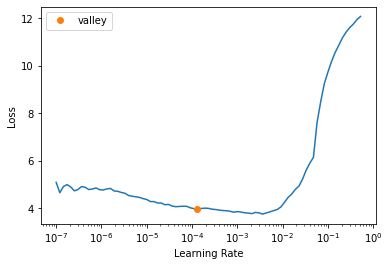

In [14]:
learn.lr_find()

It's also not a bad idea to run a batch through your model and make sure the shape of what goes in, and comes out, looks right.

In [15]:
b = dls.one_batch()
preds = learn.model(b[0])
len(preds),preds[0], preds[1].shape

(4,
 tensor(4.5574, device='cuda:0', grad_fn=<NllLossBackward>),
 torch.Size([2, 68, 50264]))

In [16]:
learn.fit_one_cycle(1, lr_max=3e-5, cbs=fit_cbs)

epoch,train_loss,valid_loss,rouge1,rouge2,rougeL,bertscore_precision,bertscore_recall,bertscore_f1,bleu,time
0,1.772397,1.580918,0.390056,0.178193,0.269924,0.878288,0.894949,0.886460,0.160391,39:41


And now we can look at the generated predictions using our `text_gen_kwargs` above

In [17]:
learn.show_results(learner=learn, max_n=2)

,text,target,prediction
0,"(CNN) -- The surviving suspect in the Boston Marathon bombings has cited the U.S. wars in Afghanistan and Iraq as motivating factors behind last week's attack, a U.S. government official said Tuesday. Dzhokhar Tsarnaev has been able to communicate with investigators in a limited fashion from his hospital bed and told them that neither he nor his brother Tamerlan, now dead, had any contact with terrorist groups overseas. The official cautioned that the interviews were preliminary, however, and that Tsarnaev's account needs to be checked out. The 19-year-old has told investigators the brothers were self-radicalized via the Internet. Investigators also are looking into whether the online English-language magazine Inspire, put out by Al Qaeda in the Arabian Peninsula, was used for instruction on how to make the bombs, but another source cautioned that other outlets could have provided that information. The twin blasts just before the finish line of the April 15 race killed three people and wounded more than 260 and turned a chunk of downtown Boston into a crime scene, disrupting the normal routines of countless others. Authorities slowly began allowing residents and business owners back into the area Tuesday. There was no word on when the street where the bombings occurred will be fully open to the public. That","NEW: Dozens remain hospitalized after last week's attack.\nAfghanistan and Iraq motivated the Boston suspects, official says.\n8-year-old victim Martin Richard laid to rest after private service.\nResidents, business owners get back into bomb blast site before public.","Dzhokhar Tsarnaev cites U.S. wars in Afghanistan and Iraq as motivating factors, official says .\nThe 19-year-old has told investigators the brothers were self-radicalized via the Internet .\nAl Qaeda magazine Inspire, put out by Al Qaeda in the Arabian Peninsula, was used for instruction on how to make bombs .\nAuthorities are allowing residents and business owners back into the area ."
1,"Washington (CNN) -- Congressional negotiators reached a tentative deal Tuesday to extend the payroll tax cut and unemployment benefits while avoiding a fee cut for Medicare doctors, according to Republican legislators and aides. The framework deal followed a key Republican concession Monday and could receive the endorsement of a House-Senate conference committee on Wednesday. Reps. Renee Ellmers of North Carolina and Fred Upton of Michigan, both Republicans who were part of the conference committee negotiations, called it a tentative agreement, while a top House Democratic aide said Democratic leaders would discuss the proposal with their members on Wednesday morning. Ellmers and Upton said they expected the conference committee to sign off on the measure Wednesday if no objections arise. In that case, the House would vote on the agreement, in the form of the conference committee report, as soon as Friday. However, some conservative House Republicans expressed concerns about the potential agreement and said they were unsure if they would support it. Other GOP House legislators said they expected it to pass with support from a majority of Republicans, as well as Democrats. ""It's the art of a deal. I mean, it's a compromise,"" said Rep. Steve Latourette, R-Ohio. ""So you have people that didn't get a 100% of what they wanted."" Under",NEW: Some Republican congressmen question the tentative agreement.\nProgress is made after Republicans back down on payroll tax cut.\nPolitical analyst Norm Ornstein warns new GOP strategy could backfire.\nPresident Obama warns that failing to act could hurt the economic recovery.,NEW: Democratic leaders will discuss the proposal with their members Wednesday morning .\nNEW: Some conservative House Republicans express concerns about the potential agreement .\nThe deal would extend the payroll tax cut and unemployment benefits while avoiding a fee cut for Medicare doctors .\nIt follows a key Republican concession Mo

Even better though, blurr augments the fastai Learner with a `blurr_summarize` method that allows you to use huggingface's `PreTrainedModel.generate` method to create something more human-like.

In [18]:
test_article = """
The past 12 months have been the worst for aviation fatalities so far this decade - with the total of number of people killed if airline 
crashes reaching 1,050 even before the Air Asia plane vanished. Two incidents involving Malaysia Airlines planes - one over eastern Ukraine and the other in the Indian Ocean - led to the deaths of 537 people, while an Air Algerie crash in Mali killed 116 and TransAsia Airways crash in Taiwan killed a further 49 people. The remaining 456 fatalities were largely in incidents involving small commercial planes or private aircraft operating on behalf of companies, governments or organisations. Despite 2014 having the highest number of fatalities so far this decade, the total number of crashes was in fact the lowest since the first commercial jet airliner took off in 1949 - totalling just 111 across the whole world over the past 12 months. The all-time deadliest year for aviation was 1972 when a staggering 2,429 people were killed in a total of 55 plane crashes - including the crash of Aeroflot Flight 217, which killed 174 people in Russia, and Convair 990 Coronado, which claimed 155 lives in Spain. However this year's total death count of 1,212, including those presumed dead on board the missing Air Asia flight, marks a significant rise on the very low 265 fatalities in 2013 - which led to it being named the safest year in aviation since the end of the Second World War. Scroll down for videos. Deadly: The past 12 months have been the worst for aviation fatalities so far this decade - with the total of number of people killed if airline crashes reaching 1,158 even before the Air Asia plane (pictured) vanished. Fatal: Two incidents involving Malaysia Airlines planes - one over eastern Ukraine (pictured) and the other in the Indian Ocean - led to the deaths of 537 people. Surprising: Despite 2014 having the highest number of fatalities so far this decade, the total number of crashes was in fact the lowest since the first commercial jet airliner took off in 1949. 2014 has been a horrific year for Malaysia-based airlines, with 537 people dying on Malaysia Airlines planes, and a further 162 people missing and feared dead in this week's Air Asia incident. In total more than half the people killed in aviation incidents this year had been flying on board Malaysia-registered planes. In January a total of 12 people lost their lives in five separate incidents, while the same number of crashes in February killed 107. 
"""

We can override the `text_gen_kwargs` we specified for our `DataLoaders` when we generate text using blurr's `Learner.blurr_generate` method

In [19]:
outputs = learn.blurr_generate(test_article, early_stopping=True, num_beams=4, num_return_sequences=3)

for idx, o in enumerate(outputs):
    print(f'=== Prediction {idx+1} ===\n{o}\n')

=== Prediction 1 ===
 The past 12 months have been the worst for aviation fatalities so far this decade .
The total number of people killed if airline crashes reached 1,158 even before Air Asia plane vanished .
Two incidents involving Malaysia Airlines planes led to the deaths of 537 people .
2014 has been a horrific year for Malaysia-based airlines, with 537 deaths on Malaysia Airlines .
More than half the people killed in aviation incidents this year had been flying on Malaysia-registered planes .

=== Prediction 2 ===
 The past 12 months have been the worst for aviation fatalities so far this decade .
The total number of people killed if airline crashes reached 1,158 even before Air Asia plane vanished .
Two incidents involving Malaysia Airlines planes led to the deaths of 537 people .
2014 has been a horrific year for Malaysia-based airlines, with 537 deaths on Malaysia Airlines .
More than half of the people killed in aviation incidents this year had been flying on Malaysia-regist

What about inference?  Easy!

In [20]:
learn.metrics = None
learn.export(fname='ft_cnndm_export.pkl')

In [21]:
inf_learn = load_learner(fname='ft_cnndm_export.pkl')
inf_learn.blurr_generate(test_article)

[' The past 12 months have been the worst for aviation fatalities so far this decade .\nThe total number of people killed if airline crashes reached 1,158 even before Air Asia plane vanished .\nTwo incidents involving Malaysia Airlines planes led to the deaths of 537 people .\n2014 has been a horrific year for Malaysia-based airlines, with 537 deaths on Malaysia Airlines .\nMore than half the people killed in aviation incidents this year had been flying on Malaysia-registered planes .']